<a href="https://colab.research.google.com/github/ChinmyeeN/MinorProject/blob/main/MP4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/content/Titanic-2.csv')

In [3]:
df.head()

,sex,age,sibsp,parch,fare,embarked,class,who,alone,survived
0,male,22.0,1,0,7.2500,S,Third,man,False,0
1,female,38.0,1,0,71.2833,C,First,woman,False,1
2,female,26.0,0,0,7.9250,S,Third,woman,True,1
3,female,35.0,1,0,53.1000,S,First,woman,False,1
4,male,35.0,0,0,8.0500,S,Third,man,True,0


In [4]:
df.tail()

,sex,age,sibsp,parch,fare,embarked,class,who,alone,survived
886,male,27.0,0,0,13.00,S,Second,man,True,0
887,female,19.0,0,0,30.00,S,First,woman,True,1
888,female,NaN,1,2,23.45,S,Third,woman,False,0
889,male,26.0,0,0,30.00,C,First,man,True,1
890,male,32.0,0,0,7.75,Q,Third,man,True,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sex       891 non-null    object 
 1   age       714 non-null    float64
 2   sibsp     891 non-null    int64  
 3   parch     891 non-null    int64  
 4   fare      891 non-null    float64
 5   embarked  889 non-null    object 
 6   class     891 non-null    object 
 7   who       891 non-null    object 
 8   alone     891 non-null    bool   
 9   survived  891 non-null    int64  
dtypes: bool(1), float64(2), int64(3), object(4)
memory usage: 63.6+ KB


In [6]:
df.isnull().sum()

,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0
alone,0
survived,0


In [8]:
df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)
df['age'].fillna(df['age'].median(), inplace=True)

/tmp/ipykernel_597/3143784167.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)
/tmp/ipykernel_597/3143784167.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=T

In [9]:
df.isnull().sum()

,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0
alone,0
survived,0


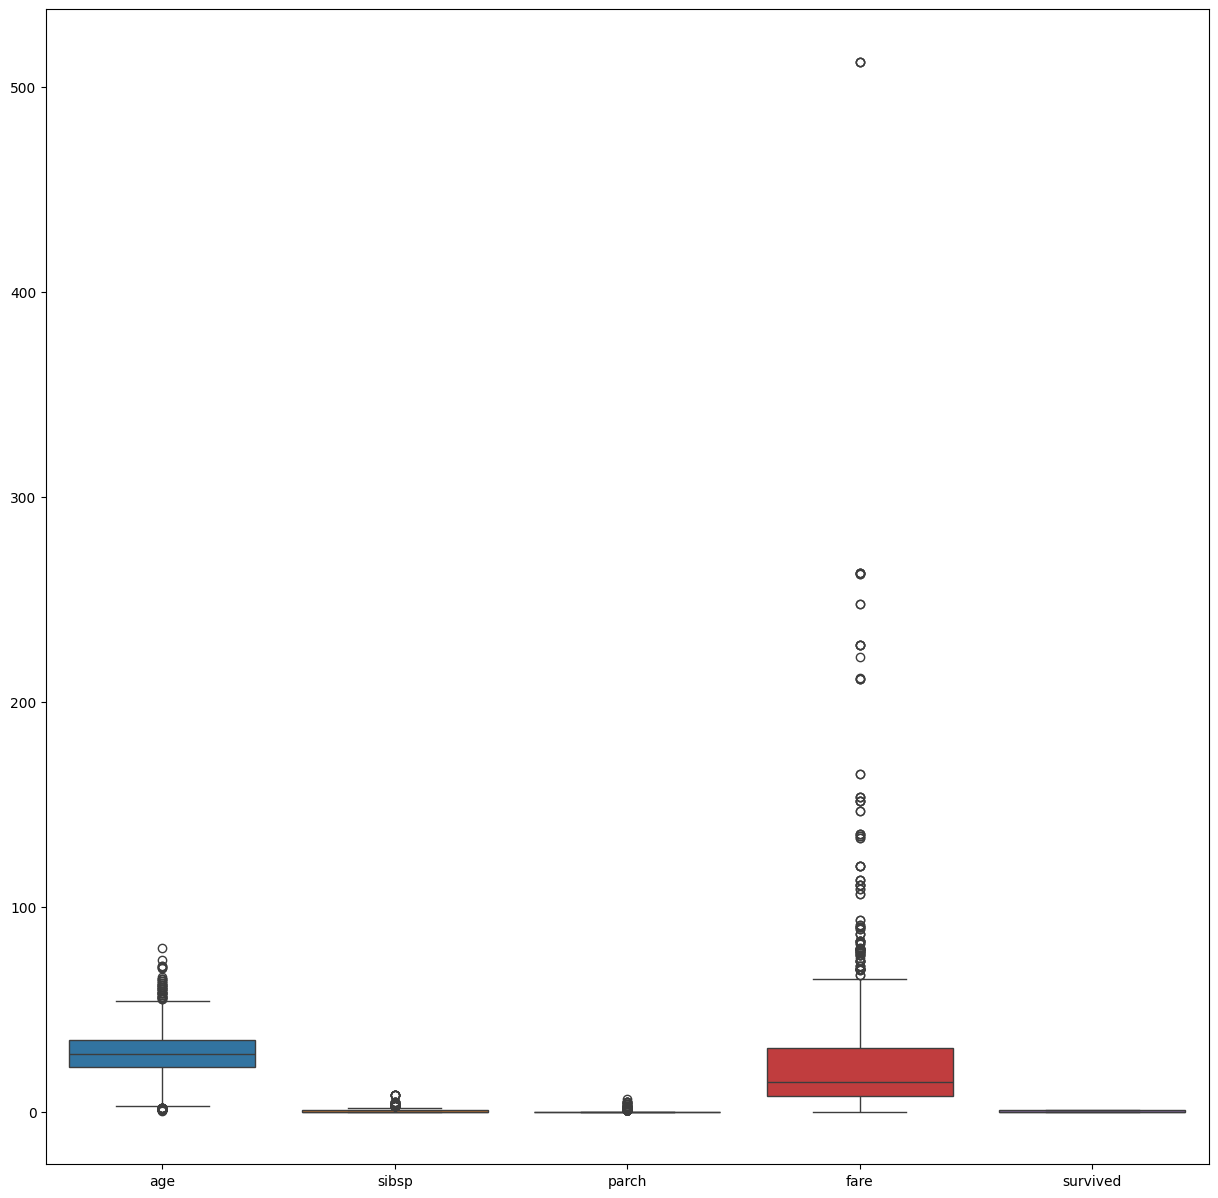

In [10]:
plt.figure(figsize=(15,15))
sns.boxplot(data = df.select_dtypes(include='number'))
plt.show()

In [19]:
df.columns = df.columns.str.strip()

columns = [
     'pclass', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'sex'
]

for i in columns:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3-Q1
  lower_bound = Q1 - 1.5*IQR
  upper_bound = Q3 + 1.5*IQR

  df[i] = np.where(df[i] < lower_bound, lower_bound, df[i])
  df[i] = np.where(df[i] > upper_bound, upper_bound, df[i])

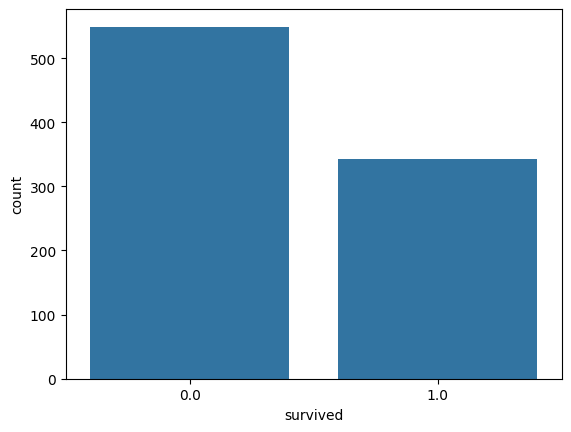

In [20]:
sns.countplot(data=df, x='survived')
plt.show()

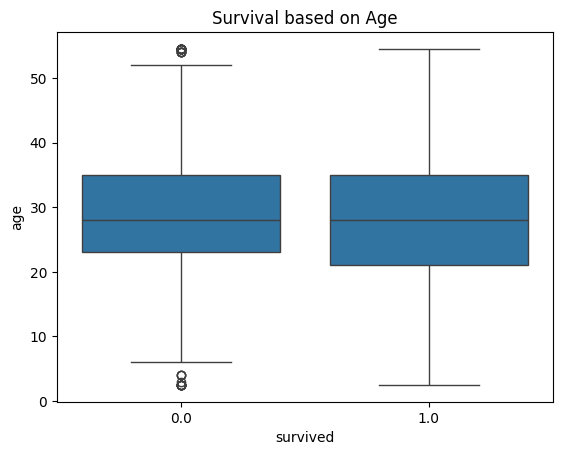

In [21]:
sns.boxplot(x='survived', y='age', data=df)
plt.title('Survival based on Age')
plt.show()

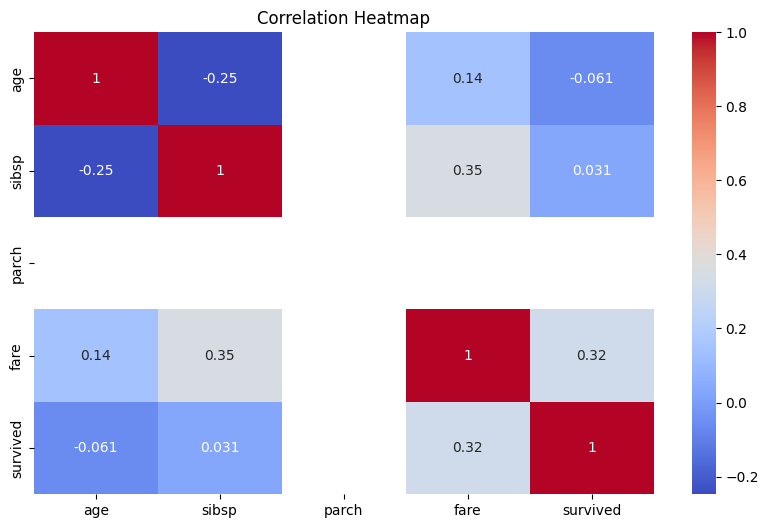

In [22]:
plt.figure(figsize=(10,6))

sns.heatmap(df.select_dtypes(include='number').corr(),
            annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

In [23]:
df.select_dtypes(include ='object').columns

Index(['sex', 'embarked', 'class', 'who'], dtype='object')

In [24]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

In [26]:
df.dtypes

,0
sex,int64
age,float64
sibsp,float64
parch,float64
fare,float64
embarked,int64
class,int64
who,int64
alone,bool
survived,float64


In [27]:
X = df.drop(columns=['embarked','survived'])
Y = df['survived']

In [28]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [29]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model.fit(X_train,Y_train)

RandomForestClassifier()

In [30]:
y_pred = model.predict(X_test)

In [31]:
print(y_pred[:10])

[0. 0. 0. 1. 0. 1. 1. 0. 0. 1.]


In [32]:
result = pd.DataFrame({'Actual':Y_test,'Predicted':y_pred})
result.head(10)

,Actual,Predicted
709,1.0,0.0
439,0.0,0.0
840,0.0,0.0
720,1.0,1.0
39,1.0,0.0
290,1.0,1.0
300,1.0,1.0
333,0.0,0.0
208,1.0,0.0
136,1.0,1.0


In [33]:
from sklearn.metrics import accuracy_score
accuracy_score(Y_test,y_pred)

0.8044692737430168

In [34]:
train_accuray = model.score(X_train,Y_train)
test_accuracy = model.score(X_test,Y_test)
print(train_accuray,test_accuracy)

0.973314606741573 0.8044692737430168


In [35]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y_test,y_pred)
print(cm)

[[89 16]
 [19 55]]


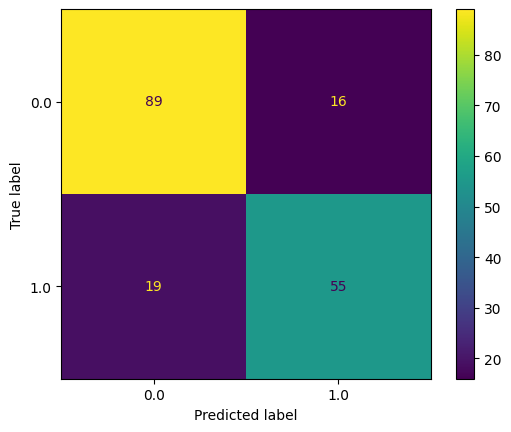

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model.classes_)
disp.plot()
plt.show()

In [37]:
from sklearn.metrics import classification_report
print(classification_report(Y_test,y_pred))

              precision    recall  f1-score   support

         0.0       0.82      0.85      0.84       105
         1.0       0.77      0.74      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.80      0.80      0.80       179



In [38]:
# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100,50, 150, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, Y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 50, 150, 200]},
             verbose=1)

In [39]:
print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}
0.8370333891460652


In [40]:
best_model = grid.best_estimator_

print("Training Accuracy:", best_model.score(X_train, Y_train))
print("Testing Accuracy:", best_model.score(X_test, Y_test))

Training Accuracy: 0.8946629213483146
Testing Accuracy: 0.8212290502793296


In [41]:
print("Before Tuning:", model.score(X_test, Y_test))
print("After Tuning:", best_model.score(X_test, Y_test))

Before Tuning: 0.8044692737430168
After Tuning: 0.8212290502793296
